# 01 · Data audit and exploration (C-NMC 2019)

Research demo. Not for clinical use.

This notebook only reads the manifest, the split file and the audit tables written by `src/download.py` and `src/split.py`. It answers: how many images and subjects survive the audit, how balanced the classes are per subject and per split, and whether color statistics differ by class (a possible stain shortcut).

In [1]:
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.utils import load_config
cfg = load_config()
DATA = Path(cfg['paths']['data_root'])
man = pd.read_csv(DATA / 'manifest.csv')
splits = pd.read_csv(ROOT / 'data' / 'splits.csv')
FIG = ROOT / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
print(len(man), 'images,', man.patient_id.nunique(), 'patient IDs,', man.group_id.nunique(), 'independent subject groups')

12068 images, 100 patient IDs, 92 independent subject groups


## Audit: what was removed and why

In [2]:
T = ROOT / 'reports' / 'tables'
corrupt = pd.read_csv(T / 'corrupt_dropped.csv'); dups = pd.read_csv(T / 'duplicates_dropped.csv'); groups = pd.read_csv(T / 'patient_groups.csv')
print('corrupt (all-zero) files dropped:', len(corrupt)); print(corrupt.groupby('patient_id').size().rename('corrupt images'))
print(); print('pixel-identical copies dropped:', len(dups), '| of which across different patient IDs:', (dups.patient_id != dups.kept_patient_id).sum())
print(); print('patient IDs merged into one subject group (shared identical images):')
print(groups[groups.n_patients > 1].to_string(index=False))

corrupt (all-zero) files dropped: 350
patient_id
49     66
67    267
68     17
Name: corrupt images, dtype: int64

pixel-identical copies dropped: 110 | of which across different patient IDs: 105

patient IDs merged into one subject group (shared identical images):
group_id    patients  n_patients  images  label
    G_20       20 21           2      85      1
    G_51 51 55 75 78           4    1094      1
   G_H10      H10 H3           2     435      0
    G_H2 H2 H4 H5 H6           4     161      0


## Class balance per split and per subject

In [3]:
s = splits.groupby('split').agg(images=('image_path','size'), subjects=('group_id','nunique'), patient_ids=('patient_id','nunique'), leukemic_frac=('label','mean'))
s.to_csv(T / 'split_summary.csv'); s

,images,subjects,patient_ids,leukemic_frac
split,,,,
test,2414,26,26,0.666529
train,7844,48,56,0.666497
val,1810,18,18,0.666298


count      92.000000
mean      131.173913
std       144.768524
min         5.000000
25%        35.000000
50%        96.500000
75%       167.500000
max      1094.000000
Name: n, dtype: float64


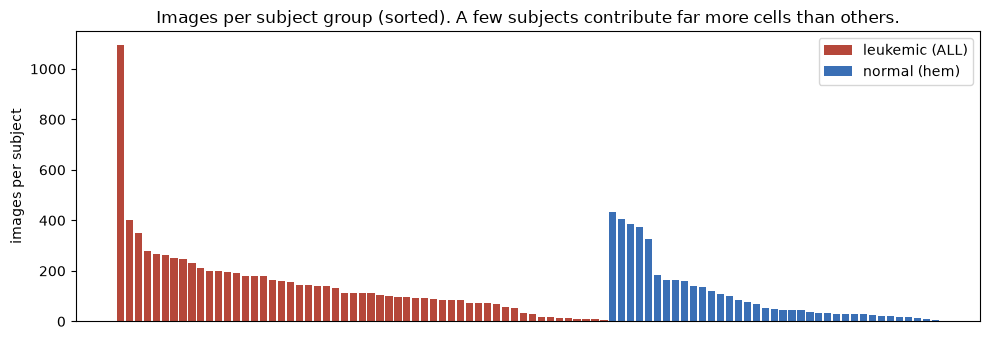

In [4]:
per = splits.groupby(['group_id','split','label']).size().rename('n').reset_index()
fig, ax = plt.subplots(figsize=(10,3.5))
for lab, c in ((1,'#b5473a'),(0,'#3a6fb5')):
    d = per[per.label==lab].sort_values('n', ascending=False)
    ax.bar(d.group_id + '·' + d.split.str[:2], d.n, color=c, label='leukemic (ALL)' if lab else 'normal (hem)')
ax.set_ylabel('images per subject'); ax.set_xticks([]); ax.legend(); ax.set_title('Images per subject group (sorted). A few subjects contribute far more cells than others.')
fig.tight_layout(); fig.savefig(FIG / 'eda_images_per_subject.png', dpi=150)
print(per.n.describe())

Because cell counts per subject are very uneven, image-level metrics are dominated by a few subjects. This is why every metric is reported with a **subject-clustered bootstrap CI**, and why patient-level metrics are reported too.

## Sample cells

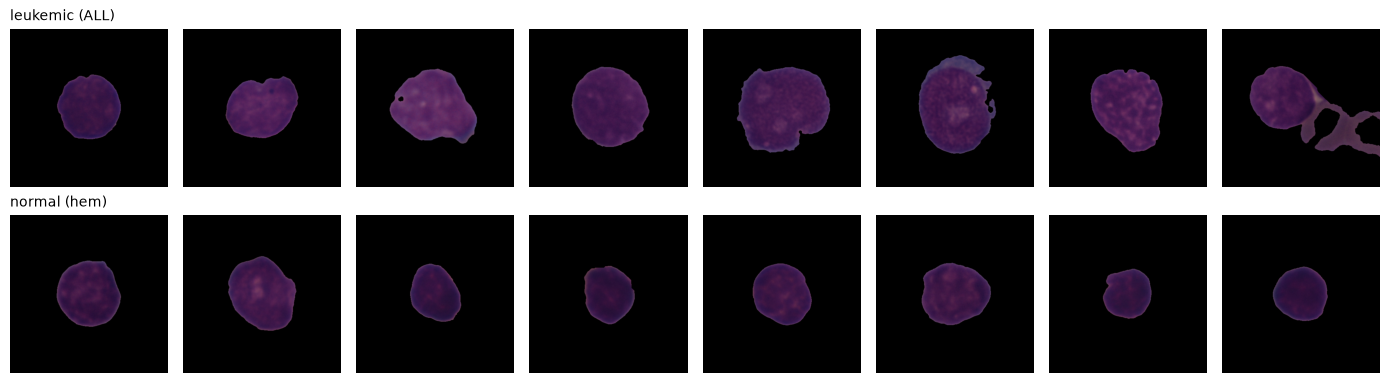

In [5]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for row, lab in enumerate((1, 0)):
    pick = man[man.label==lab].sample(8, random_state=lab)
    for ax, p in zip(axes[row], pick.image_path):
        ax.imshow(Image.open(DATA / p)); ax.axis('off')
    axes[row,0].set_title('leukemic (ALL)' if lab else 'normal (hem)', loc='left', fontsize=10)
fig.tight_layout(); fig.savefig(FIG / 'eda_samples.png', dpi=120)

## Color statistics by class (stain shortcut check)

If mean color separated the classes well, a model could score highly from stain or acquisition differences instead of morphology. Sampled 400 images per class; statistics are over the non-black (cell) pixels.

In [6]:
def stats(p):
    a = np.asarray(Image.open(DATA / p), dtype=np.float32) / 255
    m = a.sum(-1) > 0.05
    px = a[m]
    return [*px.mean(0), *px.std(0), m.mean()]
samp = pd.concat([d.sample(400, random_state=0) for _, d in man.groupby('label')])
S = pd.DataFrame([stats(p) for p in samp.image_path], columns=['R','G','B','sdR','sdG','sdB','cell_area'])
S['label'] = samp.label.to_numpy()
print(S.groupby('label').mean().round(4))
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
auc = cross_val_score(LogisticRegression(max_iter=2000), S[['R','G','B','sdR','sdG','sdB']], S.label, cv=5, scoring='roc_auc').mean()
print(f'ROC-AUC from color statistics alone (5-fold, image-level): {auc:.3f}')

            R       G       B     sdR     sdG     sdB  cell_area
label                                                           
0      0.2654  0.1153  0.3052  0.0474  0.0361  0.0421     0.1366
1      0.2767  0.1199  0.3169  0.0455  0.0349  0.0398     0.1759


ROC-AUC from color statistics alone (5-fold, image-level): 0.605


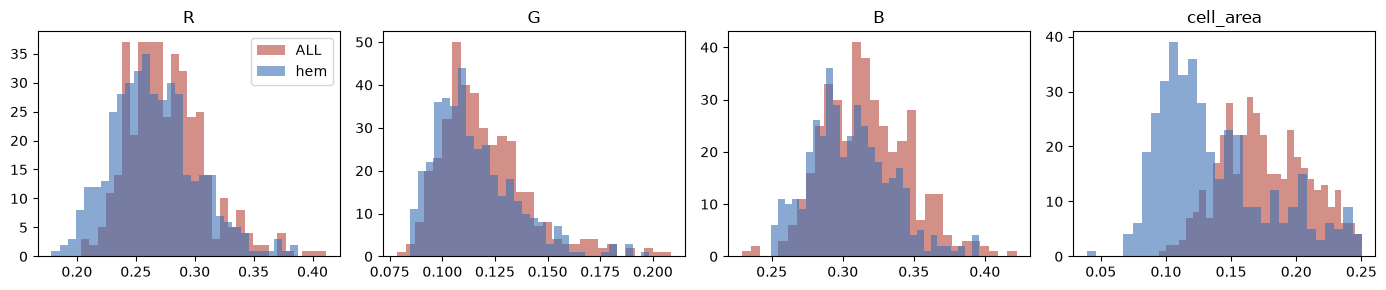

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, col in zip(axes, ['R','G','B','cell_area']):
    for lab, c in ((1,'#b5473a'),(0,'#3a6fb5')):
        ax.hist(S[S.label==lab][col], bins=30, alpha=.6, color=c, label='ALL' if lab else 'hem')
    ax.set_title(col)
axes[0].legend(); fig.tight_layout(); fig.savefig(FIG / 'eda_color_stats.png', dpi=150)

**Reading this:** a color-only ROC-AUC well above 0.5 means part of the class signal is color or size, which a CNN can exploit. The stain-augmentation and stain-normalization ablations (M5) and the external ALL-IDB2 test measure how much the model relies on it.